In [39]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision.transforms import v2
%pip install matplotlib
from matplotlib import pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 8.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 7.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [42]:
training_data= datasets.FashionMNIST(
    root = "data",
    train = True,
    download=True,
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)])
)

test_data = datasets.FashionMNIST(
    root= "data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(),v2.ToDtype(torch.float32,scale=True)])
)

In [53]:
training_data.targets,training_data.targets.shape

(tensor([9, 0, 0,  ..., 3, 0, 5]), torch.Size([60000]))

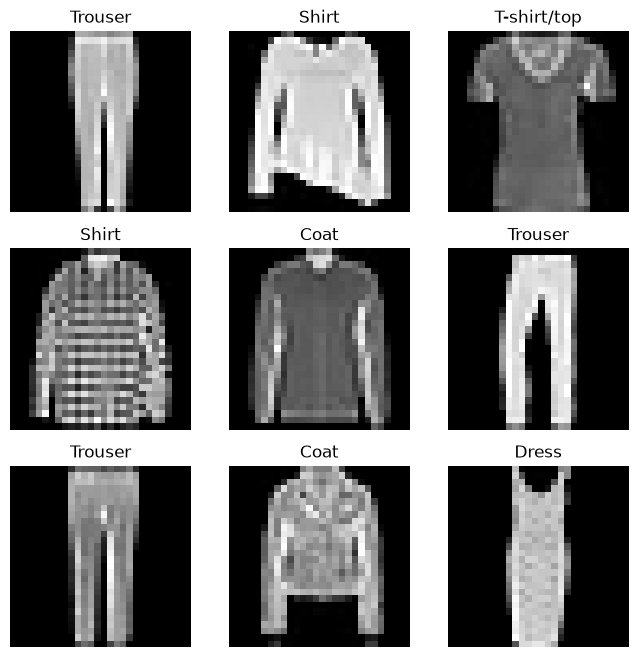

In [85]:
# labels_map = {
#     0: "T-Shirt",
#     1: "Trouser",
#     2: "Pullover",
#     3: "Dress",
#     4: "Coat",
#     5: "Sandal",
#     6: "Shirt",
#     7: "Sneaker",
#     8: "Bag",
#     9: "Ankle Boot",
# }
figure = plt.figure(figsize=(8,8))
cols,rows=3,3
for i in range(1, cols*rows +1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows,cols,i)
    plt.title(training_data.classes[label])
    plt.axis("off")
    plt.imshow(img.squeeze(),cmap="grey")
plt.show()


Image shape: torch.Size([1, 28, 28])
Numerical label: 9
Class name: Ankle Boot


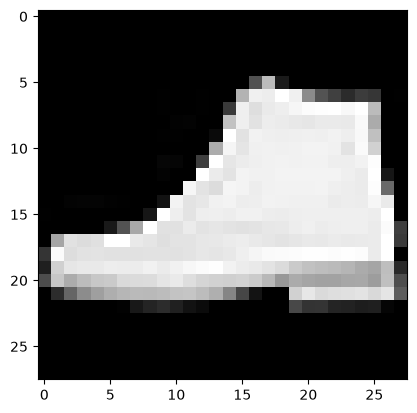

In [77]:
img, label = training_data[42]

print("Image shape:", img.shape)
print("Numerical label:", label)
print("Class name:", labels_map[label])

plt.imshow(img.squeeze(), cmap="grey")
plt.show()

In [79]:
print(training_data.classes[0])
print(training_data.class_to_idx)


T-shirt/top
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}


In [87]:
target_label = training_data.class_to_idx["Sneaker"]

sneaker_indices = torch.where(
    training_data.targets == target_label
)[0]

In [ ]:
figure = plt.figure(figsize=(10, 10))
cols, rows = 3, 3

# Get indices of all sneaker images
target_label = training_data.class_to_idx["Sneaker"]

sneaker_indices = torch.where(
    training_data.targets == target_label
)[0]

for i in range(1, cols * rows + 1):

    sample_idx = sneaker_indices[
        torch.randint(len(sneaker_indices), size=(1,)).item()
    ].item()

    img, label = training_data[sample_idx]

    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="grey")

plt.show()

NameError: name 'plt' is not defined

# Dataloaders

In [126]:
from torch.utils.data import DataLoader

train_dataloader= DataLoader(training_data,batch_size=64,shuffle=True)
test_dataloader= DataLoader(test_data,batch_size=64,shuffle=True)


Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


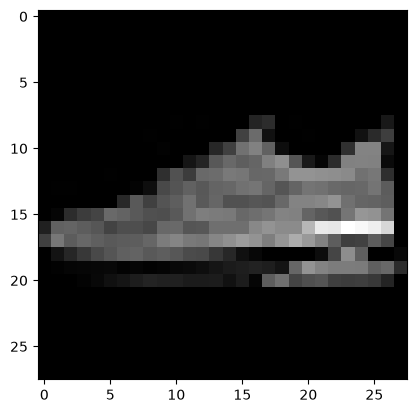

Label: 7


In [127]:
train_features, train_labels= next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img =train_features[0].squeeze()
label=train_labels[0]
plt.imshow(img,cmap="grey")
plt.show()
print(f"Label: {label}")